# Question 3

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, log_loss

### part a: dset0

In [2]:
dset0 = pd.read_csv("data/dset0-1.csv", header=None)
y0 = dset0[0].to_numpy().astype(int)
X0 = dset0.drop(columns=0).to_numpy()

X0_train, X0_test, y0_train, y0_test = train_test_split(X0, y0, test_size=0.3, stratify=y0, random_state=0)
print(f"train {len(y0_train)} | test {len(y0_test)}")
print(f"class-1 share: train {y0_train.mean():.3f} | test {y0_test.mean():.3f}")

train 350 | test 150
class-1 share: train 0.426 | test 0.427


Note: we train one classifier with 1000 trees, since we can get the smaller ones by taking the first n trees in the sum.

In [3]:
gb0 = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.1, max_depth=3, random_state=0)
gb0.fit(X0_train, y0_train)

def staged_metrics(model, X, y):
    """Accuracy and log-loss after 1, 2, ..., n_estimators trees."""
    acc, ll = [], []
    for proba in model.staged_predict_proba(X):
        acc.append(accuracy_score(y, (proba[:, 1] > 0.5).astype(int)))
        ll.append(log_loss(y, proba[:, 1]))
    return np.array(acc), np.array(ll)

curves0 = {"train": staged_metrics(gb0, X0_train, y0_train),
           "test": staged_metrics(gb0, X0_test, y0_test)}

n_trees = [1, 10, 100, 300, 1000]
idx = np.array(n_trees) - 1
pd.DataFrame({"train accuracy": curves0["train"][0][idx], "test accuracy": curves0["test"][0][idx],
              "train log-loss": curves0["train"][1][idx], "test log-loss": curves0["test"][1][idx]},
             index=pd.Index(n_trees, name="trees")).round(3)

,train accuracy,test accuracy,train log-loss,test log-loss
trees,,,,
1,0.574,0.573,0.656,0.672
10,0.829,0.680,0.502,0.588
100,0.994,0.833,0.141,0.439
300,1.000,0.840,0.023,0.519
1000,1.000,0.833,0.000,1.014


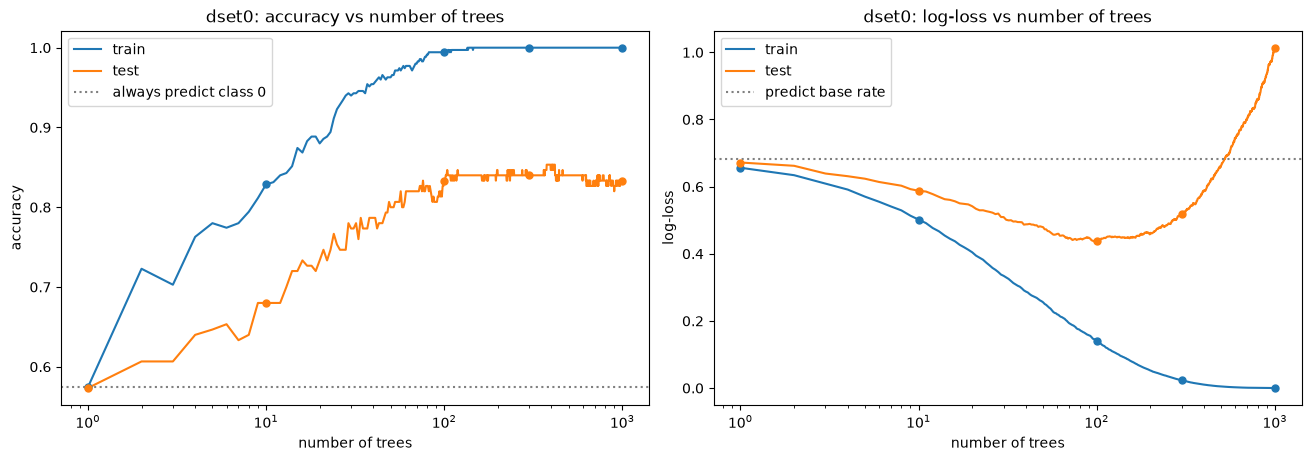

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
trees = np.arange(1, 1001)
for ax, (metric, j) in zip(axes, [("accuracy", 0), ("log-loss", 1)]):
    for split in ["train", "test"]:
        ax.plot(trees, curves0[split][j], label=split)
        ax.scatter(n_trees, curves0[split][j][idx], s=25, zorder=3)
    ax.set_xscale("log")
    ax.set_xlabel("number of trees")
    ax.set_ylabel(metric)
    ax.set_title(f"dset0: {metric} vs number of trees")
    ax.legend()
axes[0].axhline(1 - y0_train.mean(), color="gray", linestyle=":", label="always predict class 0")
axes[1].axhline(log_loss(y0_test, np.full(len(y0_test), y0_train.mean())), color="gray", linestyle=":",
                label="predict base rate")
for ax in axes:
    ax.legend()
plt.show()

Generalization behavior:
- Accuracy: the model becomes complicated enough that it can get 100% on the training data after roughly 100 trees (it fits exactly to every training point). Its judgments from then on don't change, so its performance on the test data stays similar.
- Log loss: in becoming more confident, it starts to reflect the training data too well and overfits! It remains wrong on certain examples, but its confidence in its wrong answer increases, hence the log loss does too. Thus the overall log loss actually gets worse than predicting the class-1 rate 0.426 for every point, even though its accuracy remains higher.

### part b: dset1

In [5]:
dset1 = pd.read_csv("data/dset1-1.csv", header=None)
y1 = dset1[0].to_numpy().astype(int)
X1 = dset1.drop(columns=0).to_numpy()

X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, stratify=y1, random_state=0)
print(f"train {len(y1_train)} | test {len(y1_test)} | class-1 share: train {y1_train.mean():.3f} | test {y1_test.mean():.3f}")

gb1 = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.1, max_depth=3, random_state=0)
gb1.fit(X1_train, y1_train)
curves1 = {"train": staged_metrics(gb1, X1_train, y1_train),
           "test": staged_metrics(gb1, X1_test, y1_test)}

pd.DataFrame({"train accuracy": curves1["train"][0][idx], "test accuracy": curves1["test"][0][idx],
              "train log-loss": curves1["train"][1][idx], "test log-loss": curves1["test"][1][idx]},
             index=pd.Index(n_trees, name="trees")).round(3)

train 350 | test 150 | class-1 share: train 0.454 | test 0.453


,train accuracy,test accuracy,train log-loss,test log-loss
trees,,,,
1,0.546,0.547,0.639,0.640
10,0.883,0.827,0.408,0.455
100,0.994,0.840,0.108,0.396
300,1.000,0.820,0.021,0.539
1000,1.000,0.827,0.000,1.143


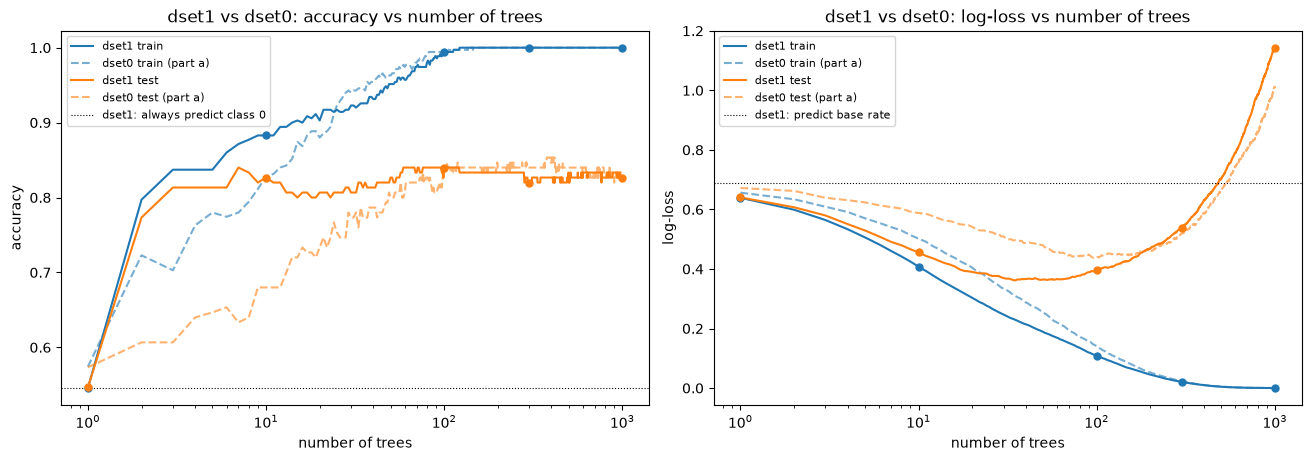

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
colors = {"train": "C0", "test": "C1"}
for ax, (metric, j) in zip(axes, [("accuracy", 0), ("log-loss", 1)]):
    for split in ["train", "test"]:
        ax.plot(trees, curves1[split][j], color=colors[split], label=f"dset1 {split}")
        ax.scatter(n_trees, curves1[split][j][idx], color=colors[split], s=25, zorder=3)
        ax.plot(trees, curves0[split][j], color=colors[split], linestyle="--", alpha=0.6, label=f"dset0 {split} (part a)")
    ax.set_xscale("log")
    ax.set_xlabel("number of trees")
    ax.set_ylabel(metric)
    ax.set_title(f"dset1 vs dset0: {metric} vs number of trees")
axes[0].axhline(1 - y1_train.mean(), color="black", linestyle=":", linewidth=0.8, label="dset1: always predict class 0")
axes[1].axhline(log_loss(y1_test, np.full(len(y1_test), y1_train.mean())), color="black", linestyle=":", linewidth=0.8,
                label="dset1: predict base rate")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

Generalization behavior:

- Accuracy: fitting the training dataset perfectly happens at a similar point in training (about 100 trees as well). However the learning is initially much faster. In particular the accuracy on the test set levels off before even reaching 10 trees, rather than the 100 required for dset0.
- Log loss: as reflected by the faster learning for accuracy, it decreases more quickly in the dset1 case than for dset0. It reaches a lower minimum, then begins rising earlier and ends on a similar trajectory. This means that there's a phase where the fitting is still continuing to help log loss (similar accuracy, more confident, and rightfully so) before ultimately overconfidence and similar dynamics to the first case play out.

### part c: explaining the difference in the data

In [7]:
for name, curves in [("dset0", curves0), ("dset1", curves1)]:
    best = int(np.argmin(curves["test"][1]))
    print(f"{name}: lowest test log-loss {curves['test'][1][best]:.3f} at {best + 1} trees | "
          f"test accuracy there {curves['test'][0][best]:.3f} | train accuracy there {curves['train'][0][best]:.3f}")

dset0: lowest test log-loss 0.437 at 96 trees | test accuracy there 0.820 | train accuracy there 0.994
dset1: lowest test log-loss 0.362 at 35 trees | test accuracy there 0.813 | train accuracy there 0.926


The optimal number of trees (computed by finding the minimum of the test log loss curve) seems for dset0 to be about 96 and dset1 to be about 35 (though it's somewhat noisy and there's a range of values near the bottom of the curve). Despite the difference in amount of trees, however, the datasets behave similarly: they achieve similar accuracy on the training and test sets, and log loss on the training and test data follow similar patterns.

We will now briefly explore why dset1 might be learned more quickly.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

datasets = {"dset0": (X0_train, X0_test, y0_train, y0_test, curves0),
            "dset1": (X1_train, X1_test, y1_train, y1_test, curves1)}
models = {"logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression()),
          "single tree, depth 1": lambda: DecisionTreeClassifier(max_depth=1, random_state=0),
          "single tree, depth 2": lambda: DecisionTreeClassifier(max_depth=2, random_state=0),
          "single tree, depth 3": lambda: DecisionTreeClassifier(max_depth=3, random_state=0)}

rows, fitted = [], {}
for model_name, make_model in models.items():
    row = {"model": model_name}
    for dname, (Xtr, Xte, ytr, yte, _) in datasets.items():
        model = make_model().fit(Xtr, ytr)
        fitted[(model_name, dname)] = model
        row[f"{dname} test acc"] = accuracy_score(yte, model.predict(Xte))
        row[f"{dname} test log-loss"] = log_loss(yte, model.predict_proba(Xte)[:, 1])
    rows.append(row)

boost_row = {"model": "boosting, best # trees (from cell above)"}
for dname, (*_, curves) in datasets.items():
    best = int(np.argmin(curves["test"][1]))
    boost_row[f"{dname} test acc"] = curves["test"][0][best]
    boost_row[f"{dname} test log-loss"] = curves["test"][1][best]
rows.append(boost_row)
display(pd.DataFrame(rows).set_index("model").round(3))

features = [f"x{j}" for j in range(1, 6)]
display(pd.DataFrame({
    "dset0 boosting importance": gb0.feature_importances_,
    "dset1 boosting importance": gb1.feature_importances_,
    "dset0 logistic coef (standardized)": fitted[("logistic regression", "dset0")][-1].coef_[0],
    "dset1 logistic coef (standardized)": fitted[("logistic regression", "dset1")][-1].coef_[0],
}, index=features).round(3))


,dset0 test acc,dset0 test log-loss,dset1 test acc,dset1 test log-loss
model,,,,
logistic regression,0.613,0.654,0.853,0.330
"single tree, depth 1",0.620,0.666,0.767,0.535
"single tree, depth 2",0.593,0.715,0.793,0.506
"single tree, depth 3",0.640,0.733,0.827,0.627
"boosting, best # trees (from cell above)",0.820,0.437,0.813,0.362


,dset0 boosting importance,dset1 boosting importance,dset0 logistic coef (standardized),dset1 logistic coef (standardized)
x1,0.396,0.506,0.102,-2.641
x2,0.172,0.213,0.476,-1.299
x3,0.210,0.097,-0.282,-0.560
x4,0.162,0.058,0.331,-0.042
x5,0.060,0.126,-0.217,0.881


This offers some view into the differences between the two datasets: logistic regression does really well to predict dset1 (better than the best trees), while it does not do as well for dset0. Hence, dset1's structure might be easier for trees to model quickly, e.g. by splitting initially based on x1, the feature with the largest regression coefficient. In contrast, dset0's structure is learnable by trees but nonlinear: feature x1 contributes a lot to boosting but has a coefficient in logistic regression that's very close to zero. Because this relationship is more complicated, it takes longer for gradient boosting to learn the pattern.